In [37]:
import tensorflow as tf
from tensorflow import keras 
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [38]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [39]:
X_train.shape

(60000, 28, 28)

In [40]:
X_train = X_train / 255
X_test = X_test / 255

In [41]:
X_train_flattened = X_train.reshape(len(X_train),28*28)
X_test_flattened = X_test.reshape(len(X_test), 28 * 28)
X_train_flattened.shape

(60000, 784)

In [42]:
X_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [43]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics =['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.8790 - loss: 0.4684
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9153 - loss: 0.3038
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9211 - loss: 0.2833
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9238 - loss: 0.2726
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9263 - loss: 0.2667


In [44]:
model.evaluate(X_test_flattened,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9260 - loss: 0.2646


[0.264579713344574, 0.9259999990463257]

In [45]:
prediction = model.predict(X_test_flattened[0:1])
predicted_digit = np.argmax(prediction[0])

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step
Predicted digit: 7
Actual digit: 7


In [46]:
prediction = model.predict(X_test_flattened)
prediction_labels = [np.argmax(i) for i in prediction]
prediction_labels[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [47]:
cm =  tf.math.confusion_matrix(labels=y_test, predictions= prediction_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 957,    0,    2,    2,    0,    6,    8,    3,    2,    0],
       [   0, 1113,    3,    2,    0,    1,    4,    2,   10,    0],
       [   3,    7,  929,   17,    8,    5,   12,   11,   38,    2],
       [   4,    0,   20,  914,    0,   29,    2,   13,   21,    7],
       [   1,    1,    5,    2,  917,    0,   10,    5,   10,   31],
       [  10,    3,    3,   29,   10,  781,   15,    5,   28,    8],
       [   9,    3,    9,    1,    7,   11,  913,    2,    3,    0],
       [   1,    5,   25,    5,    5,    0,    0,  955,    4,   28],
       [   5,    7,    7,   18,    9,   30,   10,   12,  871,    5],
       [   9,    7,    2,   10,   26,    7,    0,   28,   10,  910]],
      dtype=int32)>

Text(95.83333333333333, 0.5, 'Truth')

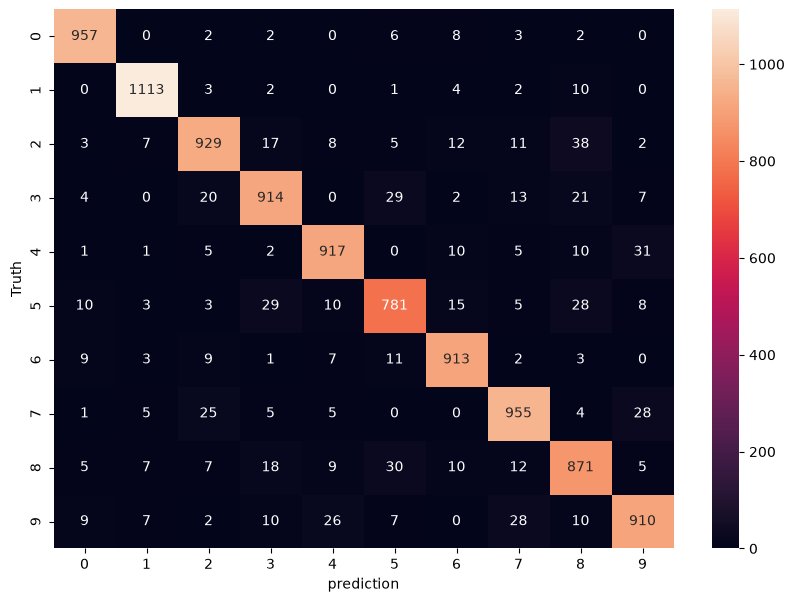

In [48]:
import seaborn as sn
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('prediction')
plt.ylabel('Truth')

In [49]:
%pip install tensorboard

Note: you may need to restart the kernel to use updated packages.


In [52]:
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation = 'relu'),
    keras.layers.Dense(10, activation = 'sigmoid')
])

tb_callback = tf.keras.callbacks.TensorBoard(log_dir='logs', histogram_freq=1)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5, callbacks=[tb_callback])

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - accuracy: 0.9230 - loss: 0.2689
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9642 - loss: 0.1220
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.9744 - loss: 0.0866
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 7ms/step - accuracy: 0.9800 - loss: 0.0672
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 9ms/step - accuracy: 0.9839 - loss: 0.0532


In [53]:
import os
import sysconfig
from pathlib import Path

tensorboard_executable = Path(sysconfig.get_path("scripts")) / (
    "tensorboard.exe" if os.name == "nt" else "tensorboard"
)
if not tensorboard_executable.is_file():
    raise FileNotFoundError(
        f"TensorBoard executable not found at {tensorboard_executable}. "
        "Run `%pip install tensorboard` in this notebook and restart the kernel."
    )
os.environ["TENSORBOARD_BINARY"] = str(tensorboard_executable)

%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12660), started 0:28:00 ago. (Use '!kill 12660' to kill it.)